<a href="https://colab.research.google.com/github/sabbirpuspo/smart-grid-stability-ml-benchmark/blob/main/smart_grid_stability_ml_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# Project: Smart Grid Stability Prediction
# Purpose: Machine Learning Benchmark
# Dataset: Electrical Grid Stability Simulated Data
# Environment: Google Colab
# ============================================================

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nProject environment initialized successfully.")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1

Project environment initialized successfully.


In [ ]:
# ============================================================
# Step 1: Mount Google Drive
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully.")

Mounted at /content/drive
Google Drive connected successfully.


In [ ]:
# ============================================================
# Step 2: Locate the dataset
# ============================================================

import os

dataset_folder = "/content/drive/MyDrive/Smart Grid Stability Dataset"

print("Files in the dataset folder:")

for filename in os.listdir(dataset_folder):
    print(filename)

Files in the dataset folder:
smart_grid_stability_augmented.csv


In [ ]:
# ============================================================
# Step 3: Load the smart-grid dataset
# ============================================================

import pandas as pd

file_path = os.path.join(
    dataset_folder,
    "smart_grid_stability_augmented.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of samples: 60000
Number of columns: 14


In [ ]:
df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [ ]:
print(df.columns.tolist())

['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4', 'stab', 'stabf']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    60000 non-null  float64
 1   tau2    60000 non-null  float64
 2   tau3    60000 non-null  float64
 3   tau4    60000 non-null  float64
 4   p1      60000 non-null  float64
 5   p2      60000 non-null  float64
 6   p3      60000 non-null  float64
 7   p4      60000 non-null  float64
 8   g1      60000 non-null  float64
 9   g2      60000 non-null  float64
 10  g3      60000 non-null  float64
 11  g4      60000 non-null  float64
 12  stab    60000 non-null  float64
 13  stabf   60000 non-null  object 
dtypes: float64(13), object(1)
memory usage: 6.4+ MB


In [ ]:
df["stabf"].value_counts()

,count
stabf,
unstable,38280
stable,21720


In [ ]:
print("Class counts:")
print(df["stabf"].value_counts())

print("\nClass percentages:")
print(
    (df["stabf"].value_counts(normalize=True) * 100).round(2)
)


Class counts:
stabf
unstable    38280
stable      21720
Name: count, dtype: int64

Class percentages:
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64


In [ ]:
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate percentage:",
    round(df.duplicated().mean() * 100, 2),
    "%"
)

Total rows: 60000
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [ ]:
print(
    pd.crosstab(
        df["stabf"],
        df["stab"] > 0,
        rownames=["Stability label"],
        colnames=["stab > 0"]
    )
)

stab > 0         False  True 
Stability label              
stable           21720      0
unstable             0  38280


stabf
unstable    38280
stable      21720
Name: count, dtype: int64


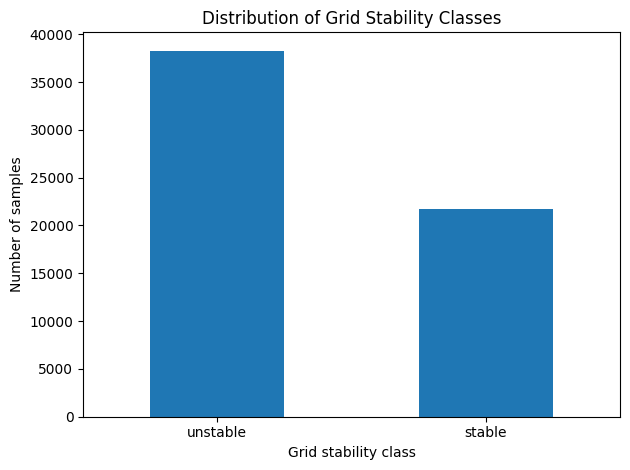

In [ ]:
class_counts = df["stabf"].value_counts()

print(class_counts)

class_counts.plot(
    kind="bar",
    xlabel="Grid stability class",
    ylabel="Number of samples",
    title="Distribution of Grid Stability Classes",
    rot=0
)

plt.tight_layout()
plt.show()


In [ ]:
print("Column data types:")
print(df.dtypes)

print("\nUnique stability labels:")
print(df["stabf"].unique())

Column data types:
tau1     float64
tau2     float64
tau3     float64
tau4     float64
p1       float64
p2       float64
p3       float64
p4       float64
g1       float64
g2       float64
g3       float64
g4       float64
stab     float64
stabf     object
dtype: object

Unique stability labels:
['unstable' 'stable']


In [ ]:
print(df["stab"].describe())

print("\nStability label versus numerical measure:")
print(pd.crosstab(df["stabf"], df["stab"] > 0))


count    60000.000000
mean         0.015731
std          0.036917
min         -0.080760
25%         -0.015557
50%          0.017142
75%          0.044878
max          0.109403
Name: stab, dtype: float64

Stability label versus numerical measure:
stab      False  True 
stabf                 
stable    21720      0
unstable      0  38280


In [ ]:
# Define the 12 input features
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

# Create input features and target
X = df[feature_columns]
y = df["stabf"]

# Check their shapes
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Preview the input features
print("\nFirst five rows of X:")
print(X.head())

print("\nFirst five target labels:")
print(y.head())

Input features shape: (60000, 12)
Target shape: (60000,)

First five rows of X:
       tau1      tau2      tau3      tau4        p1        p2        p3  \
0  2.959060  3.079885  8.381025  9.780754  3.763085 -0.782604 -1.257395   
1  9.304097  4.902524  3.047541  1.369357  5.067812 -1.940058 -1.872742   
2  8.971707  8.848428  3.046479  1.214518  3.405158 -1.207456 -1.277210   
3  0.716415  7.669600  4.486641  2.340563  3.963791 -1.027473 -1.938944   
4  3.134112  7.608772  4.943759  9.857573  3.525811 -1.125531 -1.845975   

         p4        g1        g2        g3        g4  
0 -1.723086  0.650456  0.859578  0.887445  0.958034  
1 -1.255012  0.413441  0.862414  0.562139  0.781760  
2 -0.920492  0.163041  0.766689  0.839444  0.109853  
3 -0.997374  0.446209  0.976744  0.929381  0.362718  
4 -0.554305  0.797110  0.455450  0.656947  0.820923  

First five target labels:
0    unstable
1      stable
2    unstable
3    unstable
4    unstable
Name: stabf, dtype: object


In [ ]:
# Calculate descriptive statistics for all input features
feature_summary = X.describe().T

# Display each feature's minimum, maximum, mean, and standard deviation
print(
    feature_summary[
        ["min", "max", "mean", "std"]
    ].round(4)
)

         min     max   mean     std
tau1  0.5008  9.9995  5.250  2.7424
tau2  0.5001  9.9998  5.250  2.7424
tau3  0.5001  9.9998  5.250  2.7424
tau4  0.5001  9.9998  5.250  2.7424
p1    1.5826  5.8644  3.750  0.7521
p2   -1.9999 -0.5000 -1.250  0.4330
p3   -1.9999 -0.5000 -1.250  0.4330
p4   -1.9999 -0.5000 -1.250  0.4330
g1    0.0500  0.9999  0.525  0.2742
g2    0.0500  1.0000  0.525  0.2742
g3    0.0500  1.0000  0.525  0.2742
g4    0.0500  1.0000  0.525  0.2742


In [ ]:
# Calculate correlations between the 12 input features
correlation_matrix = X.corr()

# Display the correlation matrix
print(correlation_matrix.round(2))

      tau1  tau2  tau3  tau4    p1    p2    p3    p4    g1    g2    g3    g4
tau1  1.00 -0.00 -0.00 -0.00  0.03 -0.02 -0.02 -0.02  0.01  0.01  0.01  0.01
tau2 -0.00  1.00  0.01  0.01  0.00 -0.00 -0.00 -0.00 -0.01  0.01  0.00  0.00
tau3 -0.00  0.01  1.00  0.01  0.00 -0.00 -0.00 -0.00 -0.01  0.00  0.01  0.00
tau4 -0.00  0.01  0.01  1.00  0.00 -0.00 -0.00 -0.00 -0.01  0.00  0.00  0.01
p1    0.03  0.00  0.00  0.00  1.00 -0.58 -0.58 -0.58  0.00  0.00  0.00  0.00
p2   -0.02 -0.00 -0.00 -0.00 -0.58  1.00  0.00  0.00 -0.00 -0.00  0.00  0.00
p3   -0.02 -0.00 -0.00 -0.00 -0.58  0.00  1.00  0.00 -0.00  0.00 -0.00  0.00
p4   -0.02 -0.00 -0.00 -0.00 -0.58  0.00  0.00  1.00 -0.00  0.00  0.00 -0.00
g1    0.01 -0.01 -0.01 -0.01  0.00 -0.00 -0.00 -0.00  1.00  0.00  0.00  0.00
g2    0.01  0.01  0.00  0.00  0.00 -0.00  0.00  0.00  0.00  1.00 -0.01 -0.01
g3    0.01  0.00  0.01  0.00  0.00  0.00 -0.00  0.00  0.00 -0.01  1.00 -0.01
g4    0.01  0.00  0.00  0.01  0.00  0.00  0.00 -0.00  0.00 -0.01 -0.01  1.00

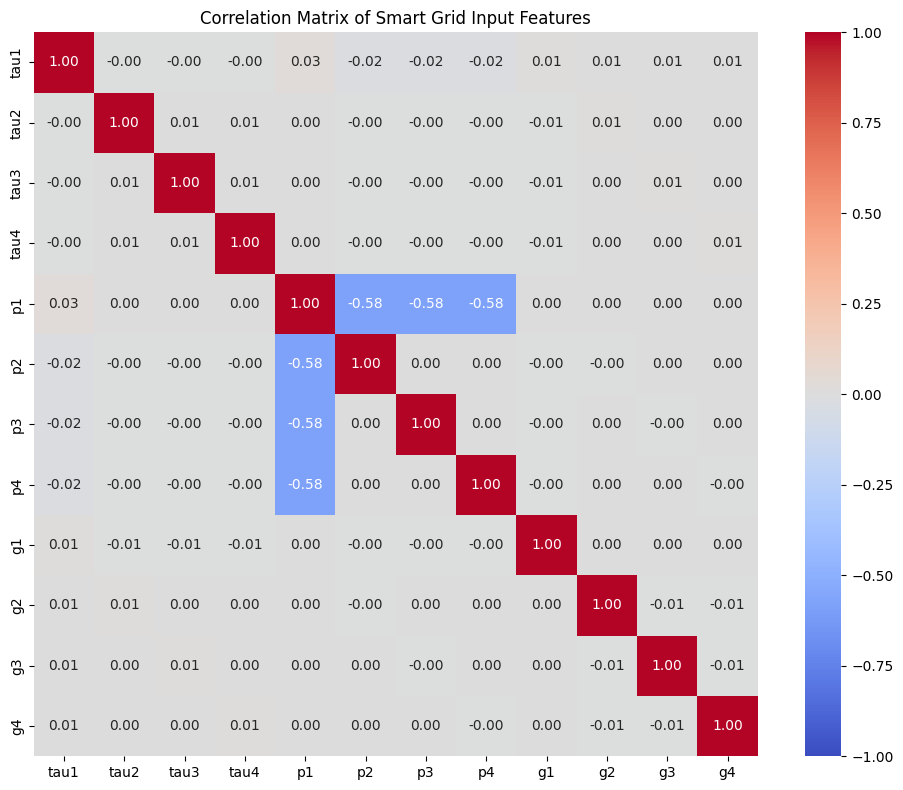

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Matrix of Smart Grid Input Features")
plt.tight_layout()
plt.show()

In [ ]:
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

X = df[feature_columns]
y = df["stabf"]

In [ ]:
print("Feature matrix X shape:", X.shape)
print("Target labels y shape:", y.shape)

print("\nTarget class counts:")
print(y.value_counts())

print("\nTarget class proportions (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Feature matrix X shape: (60000, 12)
Target labels y shape: (60000,)

Target class counts:
stabf
unstable    38280
stable      21720
Name: count, dtype: int64

Target class proportions (%):
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [ ]:
import numpy as np

# Calculate p1 from the three consumer power values
p1_calculated = (
    df["p2"] + df["p3"] + df["p4"]
).abs()

# Measure the difference from the recorded p1
p1_error = (df["p1"] - p1_calculated).abs()

print("Rows in dataset:", len(df))
print(
    "Rows where p1 matches the formula:",
    np.isclose(
        df["p1"],
        p1_calculated,
        atol=1e-8
    ).sum()
)
print("Maximum absolute difference:", p1_error.max())

Rows in dataset: 60000
Rows where p1 matches the formula: 60000
Maximum absolute difference: 6.217248937900877e-15


In [ ]:
# Sort the three consumer nodes into a canonical order.
# Each consumer node is represented by its tau, p, and g values.

def canonical_key(row):
    consumer_nodes = [
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),

        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),

        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ]

    # Sorting makes the key independent of consumer-node order.
    consumer_nodes = tuple(sorted(consumer_nodes))

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        consumer_nodes,
        round(row["stab"], 8),
        row["stabf"]
    )


# Create a canonical key for every row
canonical_keys = df.apply(canonical_key, axis=1)

# Count how many rows correspond to each canonical configuration
group_sizes = canonical_keys.value_counts()

print("Total rows:", len(df))
print("Unique canonical configurations:", len(group_sizes))
print(
    "Groups containing exactly 6 rows:",
    (group_sizes == 6).sum()
)
print(
    "Groups containing a different number of rows:",
    (group_sizes != 6).sum()
)

print("\nDistribution of group sizes:")
print(group_sizes.value_counts().sort_index())

Total rows: 60000
Unique canonical configurations: 10000
Groups containing exactly 6 rows: 10000
Groups containing a different number of rows: 0

Distribution of group sizes:
count
6    10000
Name: count, dtype: int64


In [ ]:
# Create a canonical key using system inputs only.
# Do not include stab or stabf in this key.

def canonical_input_key(row):
    consumer_nodes = [
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),

        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),

        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ]

    # Ignore the ordering of the three consumer nodes.
    consumer_nodes = tuple(sorted(consumer_nodes))

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        consumer_nodes
    )


# Assign the same group ID to equivalent configurations.
canonical_input_keys = df.apply(canonical_input_key, axis=1)
group_ids = pd.factorize(canonical_input_keys)[0]

# Examine each group and its target labels.
group_summary = (
    df.assign(group_id=group_ids)
      .groupby("group_id")
      .agg(
          row_count=("stabf", "size"),
          unique_labels=("stabf", "nunique"),
          unique_stability_values=("stab", "nunique")
      )
)

print("Unique input configurations:", len(group_summary))

print("\nDistribution of group sizes:")
print(group_summary["row_count"].value_counts().sort_index())

print(
    "\nGroups with inconsistent target labels:",
    (group_summary["unique_labels"] > 1).sum()
)

print(
    "Groups with inconsistent stability values:",
    (group_summary["unique_stability_values"] > 1).sum()
)

Unique input configurations: 10000

Distribution of group sizes:
row_count
6    10000
Name: count, dtype: int64

Groups with inconsistent target labels: 0
Groups with inconsistent stability values: 0


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Step 1: Select the 11 input features
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

X = df[feature_columns]
y = df["stabf"]

print("Input features:", len(feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

Input features: 11
X shape: (60000, 11)
y shape: (60000,)


In [ ]:
# Create a table containing one entry per unique configuration
group_table = pd.DataFrame({
    "group_id": group_ids,
    "target": y.to_numpy()
}).drop_duplicates(subset="group_id")

print("Unique configurations:", len(group_table))

# Split configurations into 80% training and 20% testing.
# Stratification preserves the class proportions.
train_group_ids, test_group_ids = train_test_split(
    group_table["group_id"].to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=group_table["target"]
)

# Assign all six permutations of each configuration
# to the same split.
train_mask = np.isin(group_ids, train_group_ids)
test_mask = np.isin(group_ids, test_group_ids)

train_idx = np.flatnonzero(train_mask)
test_idx = np.flatnonzero(test_mask)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Check that no configuration appears in both sets
train_groups = np.unique(group_ids[train_idx])
test_groups = np.unique(group_ids[test_idx])

print("\nTraining configurations:", len(train_groups))
print("Testing configurations:", len(test_groups))
print(
    "Configurations shared between sets:",
    len(np.intersect1d(train_groups, test_groups))
)

Unique configurations: 10000

Training features: (48000, 11)
Testing features: (12000, 11)

Training target distribution:
stabf
unstable    30624
stable      17376
Name: count, dtype: int64

Testing target distribution:
stabf
unstable    7656
stable      4344
Name: count, dtype: int64

Training configurations: 8000
Testing configurations: 2000
Configurations shared between sets: 0


In [ ]:
# Step 1: Import the required tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Step 2: Build the model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Step 3: Train the model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict the labels for the unseen test data
y_pred = logistic_model.predict(X_test)

# Calculate the probability of the "unstable" class
unstable_index = list(logistic_model.classes_).index("unstable")
y_prob = logistic_model.predict_proba(X_test)[:, unstable_index]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(
    (y_test == "unstable").astype(int),
    y_prob
)

print("=== Logistic Regression: Test Results ===")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["stable", "unstable"]
))

=== Logistic Regression: Test Results ===
Accuracy:          0.8200
Balanced accuracy: 0.7941
ROC-AUC:           0.8919

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.7800    0.7003    0.7380      4344
    unstable     0.8393    0.8879    0.8629      7656

    accuracy                         0.8200     12000
   macro avg     0.8096    0.7941    0.8005     12000
weighted avg     0.8178    0.8200    0.8177     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3042 1302]
 [ 858 6798]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train using the same training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict classes and probabilities
rf_pred = rf_model.predict(X_test)

unstable_index = list(rf_model.classes_).index("unstable")
rf_prob = rf_model.predict_proba(X_test)[:, unstable_index]

# Calculate metrics
print("=== Random Forest: Test Results ===")
print(f"Accuracy:          {accuracy_score(y_test, rf_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, rf_pred):.4f}"
)
print(
    f"ROC-AUC:           "
    f"{roc_auc_score((y_test == 'unstable').astype(int), rf_prob):.4f}"
)

print("\n=== Classification Report ===")
print(classification_report(y_test, rf_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(confusion_matrix(
    y_test,
    rf_pred,
    labels=["stable", "unstable"]
))

=== Random Forest: Test Results ===
Accuracy:          0.9357
Balanced accuracy: 0.9268
ROC-AUC:           0.9879

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.9257    0.8943    0.9097      4344
    unstable     0.9412    0.9592    0.9501      7656

    accuracy                         0.9357     12000
   macro avg     0.9334    0.9268    0.9299     12000
weighted avg     0.9356    0.9357    0.9355     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3885  459]
 [ 312 7344]]


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train using the existing training set
gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Generate predictions on the existing test set
gb_pred = gb_model.predict(X_test)

# Extract the probability for the unstable class
unstable_index = list(gb_model.classes_).index("unstable")
gb_prob = gb_model.predict_proba(X_test)[:, unstable_index]

print("=== Gradient Boosting: Test Results ===")
print(f"Accuracy:          {accuracy_score(y_test, gb_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, gb_pred):.4f}"
)
print(
    f"ROC-AUC:           "
    f"{roc_auc_score((y_test == 'unstable').astype(int), gb_prob):.4f}"
)

print("\n=== Classification Report ===")
print(classification_report(y_test, gb_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(
    confusion_matrix(
        y_test,
        gb_pred,
        labels=["stable", "unstable"]
    )
)

=== Gradient Boosting: Test Results ===
Accuracy:          0.9290
Balanced accuracy: 0.9131
ROC-AUC:           0.9818

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.9431    0.8554    0.8972      4344
    unstable     0.9221    0.9707    0.9458      7656

    accuracy                         0.9290     12000
   macro avg     0.9326    0.9131    0.9215     12000
weighted avg     0.9297    0.9290    0.9282     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3716  628]
 [ 224 7432]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Store predictions and probabilities from our three models
model_results = {
    "Logistic Regression": (y_pred, y_prob),
    "Random Forest": (rf_pred, rf_prob),
    "Gradient Boosting": (gb_pred, gb_prob)
}

rows = []

for model_name, (predictions, probabilities) in model_results.items():

    # Confusion matrix order: stable, unstable
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["stable", "unstable"]
    )

    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "unstable").astype(int),
            probabilities
        ),
        "Stable recall": recall_score(
            y_test, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

comparison_df = pd.DataFrame(rows)

# Sort by balanced accuracy for this preliminary comparison
comparison_df = comparison_df.sort_values(
    by="Balanced accuracy",
    ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
      Random Forest    0.9358             0.9268   0.9879         0.8943           0.9592                    312           459
  Gradient Boosting    0.9290             0.9131   0.9818         0.8554           0.9707                    224           628
Logistic Regression    0.8200             0.7941   0.8919         0.7003           0.8879                    858          1302


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract Random Forest feature importance scores
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("=== Random Forest Feature Importance ===")
print(importance_df.to_string(
    index=False,
    formatters={"Importance": "{:.4f}".format}
))

=== Random Forest Feature Importance ===
Feature Importance
   tau1     0.1306
   tau2     0.1267
   tau4     0.1261
   tau3     0.1255
     g1     0.1066
     g3     0.1049
     g4     0.1048
     g2     0.1033
     p4     0.0238
     p3     0.0238
     p2     0.0238


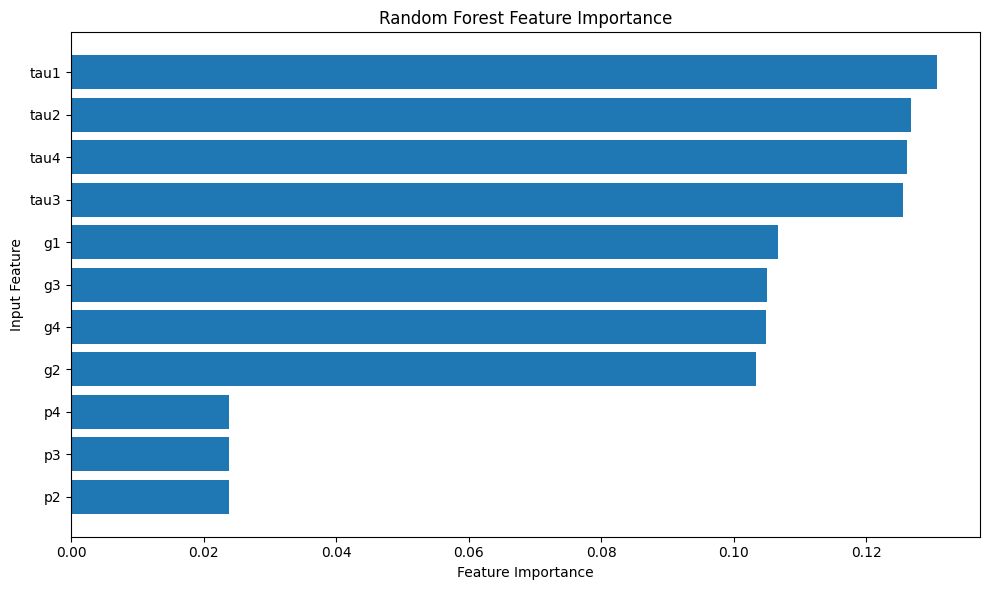

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Input Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import balanced_accuracy_score

# Baseline performance on the held-out test set
baseline_predictions = rf_model.predict(X_test)

baseline_score = balanced_accuracy_score(
    y_test,
    baseline_predictions
)

# Group related input features
feature_groups = {
    "Time constants (tau)": [
        "tau1", "tau2", "tau3", "tau4"
    ],
    "Conductance parameters (g)": [
        "g1", "g2", "g3", "g4"
    ],
    "Power parameters (p)": [
        "p2", "p3", "p4"
    ]
}

rng = np.random.default_rng(42)
n_repeats = 10
group_results = []

for group_name, columns in feature_groups.items():

    score_drops = []

    for repeat in range(n_repeats):

        # Create a copy of the original test features
        X_permuted = X_test.copy()

        # Shuffle the selected feature family together
        shuffled_indices = rng.permutation(len(X_test))

        X_permuted.loc[:, columns] = (
            X_test.iloc[shuffled_indices][columns].to_numpy()
        )

        # Evaluate after disrupting the relationship
        # between this feature family and the target
        permuted_predictions = rf_model.predict(X_permuted)

        permuted_score = balanced_accuracy_score(
            y_test,
            permuted_predictions
        )

        score_drops.append(
            baseline_score - permuted_score
        )

    group_results.append({
        "Feature family": group_name,
        "Mean balanced-accuracy drop": np.mean(score_drops),
        "Standard deviation": np.std(score_drops, ddof=1)
    })

group_importance_df = pd.DataFrame(group_results)

print(f"Baseline balanced accuracy: {baseline_score:.4f}")
print("\n=== Grouped Permutation Importance ===")
print(group_importance_df.round(4).to_string(index=False))

Baseline balanced accuracy: 0.9268

=== Grouped Permutation Importance ===
            Feature family  Mean balanced-accuracy drop  Standard deviation
      Time constants (tau)                       0.3352              0.0043
Conductance parameters (g)                       0.2440              0.0032
      Power parameters (p)                      -0.0010              0.0008


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Keep only the tau and g feature families
tau_g_features = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]

# Train a new Random Forest with the same settings
rf_tau_g_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_tau_g_model.fit(
    X_train[tau_g_features],
    y_train
)

print("Reduced Random Forest training completed!")
print("Number of input features:", len(tau_g_features))

Reduced Random Forest training completed!
Number of input features: 8


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Get predictions and probabilities for the 11-feature model
rf_full_pred = rf_model.predict(X_test)

rf_full_prob = rf_model.predict_proba(X_test)[
    :, list(rf_model.classes_).index("unstable")
]

# Get predictions and probabilities for the 8-feature model
rf_reduced_pred = rf_tau_g_model.predict(
    X_test[tau_g_features]
)

rf_reduced_prob = rf_tau_g_model.predict_proba(
    X_test[tau_g_features]
)[:, list(rf_tau_g_model.classes_).index("unstable")]

# Verify probability array lengths
print("Test labels:", len(y_test))
print("Full-model probabilities:", len(rf_full_prob))
print("Reduced-model probabilities:", len(rf_reduced_prob))

# Compare both models
models = {
    "Random Forest: 11 features": (rf_full_pred, rf_full_prob),
    "Random Forest: 8 features": (rf_reduced_pred, rf_reduced_prob)
}

comparison = []

for name, (pred, prob) in models.items():
    cm = confusion_matrix(
        y_test,
        pred,
        labels=["stable", "unstable"]
    )

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(
            (y_test == "unstable").astype(int),
            prob
        ),
        "Stable recall": recall_score(
            y_test, pred, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, pred, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

ablation_results = pd.DataFrame(comparison)

print("\n=== Feature Ablation Results ===")
print(ablation_results.round(4).to_string(index=False))

Test labels: 12000
Full-model probabilities: 12000
Reduced-model probabilities: 12000

=== Feature Ablation Results ===
                     Model  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
Random Forest: 11 features    0.9358             0.9268   0.9879         0.8943           0.9592                    312           459
 Random Forest: 8 features    0.9409             0.9319   0.9895         0.8994           0.9645                    272           437


In [40]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    make_scorer
)

# Recover the configuration groups corresponding to training rows
groups_train = np.asarray(group_ids)[train_idx]

print("Training rows:", len(X_train))
print("Unique training configurations:", len(np.unique(groups_train)))

# Five folds, stratified by class and separated by configuration group
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate both feature sets using the same folds
feature_sets = {
    "Random Forest: 11 features": list(X_train.columns),
    "Random Forest: 8 features": tau_g_features
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": make_scorer(balanced_accuracy_score),
    "roc_auc": "roc_auc",
    "stable_recall": make_scorer(
        recall_score, pos_label="stable"
    ),
    "unstable_recall": make_scorer(
        recall_score, pos_label="unstable"
    )
}

cv_rows = []

for model_name, features in feature_sets.items():

    print(f"\nEvaluating {model_name}...")

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_validate(
        model,
        X_train[features],
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    row = {"Model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} std"] = values.std(ddof=1)

    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)

print("\n=== Five-Fold Group Cross-Validation Results ===")
print(cv_results.round(4).to_string(index=False))

Training rows: 48000
Unique training configurations: 8000

Evaluating Random Forest: 11 features...

Evaluating Random Forest: 8 features...

=== Five-Fold Group Cross-Validation Results ===
                     Model  accuracy mean  accuracy std  balanced_accuracy mean  balanced_accuracy std  roc_auc mean  roc_auc std  stable_recall mean  stable_recall std  unstable_recall mean  unstable_recall std
Random Forest: 11 features         0.9334        0.0070                  0.9245                 0.0081        0.9855       0.0027              0.8919             0.0152                0.9570               0.0076
 Random Forest: 8 features         0.9367        0.0081                  0.9280                 0.0096        0.9872       0.0023              0.8963             0.0174                0.9596               0.0069


In [41]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score
)

# Reuse the same five group-aware folds
fold_splits = list(
    cv.split(X_train, y_train, groups=groups_train)
)

feature_sets = {
    "11 features": list(X_train.columns),
    "8 features": tau_g_features
}

fold_results = []

for fold_number, (fit_idx, val_idx) in enumerate(
    fold_splits, start=1
):
    X_fit = X_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]

    y_fit = y_train.iloc[fit_idx]
    y_val = y_train.iloc[val_idx]

    for model_name, features in feature_sets.items():

        model = RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fit[features], y_fit)

        predictions = model.predict(X_val[features])

        unstable_index = list(model.classes_).index("unstable")
        probabilities = model.predict_proba(
            X_val[features]
        )[:, unstable_index]

        fold_results.append({
            "Fold": fold_number,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "ROC-AUC": roc_auc_score(
                (y_val == "unstable").astype(int),
                probabilities
            )
        })

fold_results_df = pd.DataFrame(fold_results)

print("=== Performance by Validation Fold ===")
print(fold_results_df.round(4).to_string(index=False))

=== Performance by Validation Fold ===
 Fold       Model  Accuracy  Balanced accuracy  ROC-AUC
    1 11 features    0.9347             0.9248   0.9860
    1  8 features    0.9355             0.9265   0.9876
    2 11 features    0.9299             0.9189   0.9848
    2  8 features    0.9323             0.9217   0.9863
    3 11 features    0.9375             0.9268   0.9865
    3  8 features    0.9382             0.9270   0.9883
    4 11 features    0.9416             0.9364   0.9886
    4  8 features    0.9494             0.9443   0.9900
    5 11 features    0.9234             0.9155   0.9814
    5  8 features    0.9279             0.9204   0.9837


In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
import pandas as pd

# Use 3 group-aware folds for a faster initial search
cv_fast = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Smaller search space
param_distributions_fast = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.8]
}

# Keep the model focused on our selected 8 features
rf_base_fast = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_search_fast = RandomizedSearchCV(
    estimator=rf_base_fast,
    param_distributions=param_distributions_fast,
    n_iter=6,
    scoring="balanced_accuracy",
    refit=True,
    cv=cv_fast,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=False
)

print("Starting the faster hyperparameter search...")

rf_search_fast.fit(
    X_train[tau_g_features],
    y_train,
    groups=groups_train
)

print("\nSearch completed!")
print("\nBest parameters:")
print(rf_search_fast.best_params_)

print(
    "\nBest mean cross-validation balanced accuracy:",
    round(rf_search_fast.best_score_, 4)
)

# Show the tested configurations
search_results_fast = pd.DataFrame(
    rf_search_fast.cv_results_
)

print("\n=== Tested Configurations ===")
print(
    search_results_fast[
        [
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
    .to_string(index=False)
)

Starting the faster hyperparameter search...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   7.3s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   6.4s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   6.9s
[CV] END max_depth=20, max_features=0.8, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  25.3s
[CV] END max_depth=20, max_features=0.8, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  26.5s
[CV] END max_depth=20, max_features=0.8, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  27.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=  13.9s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

# Baseline model: our original 300-tree Random Forest
baseline_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Tuned model: best parameters from the search
tuned_model = RandomForestClassifier(
    **rf_search_fast.best_params_,
    random_state=42,
    n_jobs=-1
)

# Evaluate both models using identical folds
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

comparison_rows = []

for model_name, model in [
    ("Baseline: 8 features", baseline_model),
    ("Tuned: 8 features", tuned_model)
]:
    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        model,
        X_train[tau_g_features],
        y_train,
        groups=groups_train,
        cv=cv_fast,
        scoring=scoring,
        n_jobs=1
    )

    comparison_rows.append({
        "Model": model_name,
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Balanced accuracy mean":
            scores["test_balanced_accuracy"].mean(),
        "Balanced accuracy std":
            scores["test_balanced_accuracy"].std(ddof=1),
        "ROC-AUC mean": scores["test_roc_auc"].mean()
    })

fair_comparison = pd.DataFrame(comparison_rows)

print("\n=== Fair 3-Fold Comparison ===")
print(fair_comparison.round(4).to_string(index=False))

Evaluating Baseline: 8 features...
Evaluating Tuned: 8 features...

=== Fair 3-Fold Comparison ===
               Model  Accuracy mean  Balanced accuracy mean  Balanced accuracy std  ROC-AUC mean
Baseline: 8 features         0.9336                  0.9248                 0.0026        0.9857
   Tuned: 8 features         0.9332                  0.9239                 0.0016        0.9847


In [44]:
import pandas as pd

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score

# Compare all models using the same 8 features
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Evaluate both classes, not only the majority class
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "stable_recall": make_scorer(
        recall_score, pos_label="stable"
    ),
    "unstable_recall": make_scorer(
        recall_score, pos_label="unstable"
    )
}

results = []

for model_name, model in models.items():
    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        model,
        X_train[tau_g_features],
        y_train,
        groups=groups_train,
        cv=cv,                  # Same 5 group-aware folds
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    row = {"Model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} std"] = values.std(ddof=1)

    results.append(row)

model_comparison = pd.DataFrame(results)

print("\n=== Five-Fold Group-Aware Model Comparison ===")
print(model_comparison.round(4).to_string(index=False))

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...

=== Five-Fold Group-Aware Model Comparison ===
              Model  accuracy mean  accuracy std  balanced_accuracy mean  balanced_accuracy std  roc_auc mean  roc_auc std  stable_recall mean  stable_recall std  unstable_recall mean  unstable_recall std
Logistic Regression         0.8121        0.0159                  0.7874                 0.0166        0.8902       0.0102              0.6979             0.0241                0.8770               0.0187
      Random Forest         0.9367        0.0081                  0.9280                 0.0096        0.9872       0.0023              0.8963             0.0174                0.9596               0.0069
  Gradient Boosting         0.9128        0.0063                  0.8925                 0.0080        0.9752       0.0035              0.8190             0.0186                0.9660               0.0063


In [45]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Use our selected 8-feature model
rf_cv_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Each training observation receives a prediction from a model
# that did not train on that observation's configuration group.
oof_probabilities = cross_val_predict(
    rf_cv_model,
    X_train[tau_g_features],
    y_train,
    groups=groups_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

# Find the probability column corresponding to "unstable"
classes = np.unique(y_train)
unstable_index = np.where(classes == "unstable")[0][0]

oof_unstable_prob = oof_probabilities[:, unstable_index]

print("Training observations:", len(y_train))
print("Out-of-fold predictions:", len(oof_unstable_prob))
print("Unique configuration groups:", len(np.unique(groups_train)))
print("Cross-validated probabilities generated successfully!")

Training observations: 48000
Out-of-fold predictions: 48000
Unique configuration groups: 8000
Cross-validated probabilities generated successfully!


In [46]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:

    # Predict unstable whenever its probability meets the threshold
    predictions = np.where(
        oof_unstable_prob >= threshold,
        "unstable",
        "stable"
    )

    cm = confusion_matrix(
        y_train,
        predictions,
        labels=["stable", "unstable"]
    )

    threshold_results.append({
        "Threshold": threshold,
        "Balanced accuracy": balanced_accuracy_score(
            y_train, predictions
        ),
        "Stable recall": recall_score(
            y_train, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_train, predictions, pos_label="unstable"
        ),
        "Unstable precision": precision_score(
            y_train, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

threshold_df = pd.DataFrame(threshold_results)

print("=== Threshold Analysis: Training OOF Predictions ===")
print(threshold_df.round(4).to_string(index=False))

=== Threshold Analysis: Training OOF Predictions ===
 Threshold  Balanced accuracy  Stable recall  Unstable recall  Unstable precision  Unstable cases missed  False alarms
      0.30             0.8540         0.7126           0.9954              0.8592                    141          4994
      0.35             0.8801         0.7695           0.9907              0.8834                    284          4006
      0.40             0.8996         0.8161           0.9830              0.9041                    520          3195
      0.45             0.9148         0.8562           0.9734              0.9227                    816          2498
      0.50             0.9270         0.8933           0.9608              0.9407                   1201          1854
      0.55             0.9357         0.9275           0.9440              0.9582                   1716          1260
      0.60             0.9379         0.9517           0.9241              0.9712                   2324          

In [47]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix
)

# Obtain probabilities from the existing 8-feature model
test_probabilities = rf_tau_g_model.predict_proba(
    X_test[tau_g_features]
)

unstable_index = list(
    rf_tau_g_model.classes_
).index("unstable")

test_unstable_prob = test_probabilities[:, unstable_index]

threshold_test_results = []

for threshold in [0.50, 0.60]:

    # Apply the selected threshold
    predictions = [
        "unstable" if prob >= threshold else "stable"
        for prob in test_unstable_prob
    ]

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["stable", "unstable"]
    )

    threshold_test_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Stable recall": recall_score(
            y_test, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable precision": precision_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

test_threshold_df = pd.DataFrame(threshold_test_results)

print("=== Test-Set Threshold Comparison ===")
print(test_threshold_df.round(4).to_string(index=False))

=== Test-Set Threshold Comparison ===
 Threshold  Accuracy  Balanced accuracy  Stable recall  Unstable recall  Unstable precision  Unstable cases missed  False alarms
       0.5    0.9406             0.9312         0.8973           0.9651              0.9431                    267           446
       0.6    0.9362             0.9408         0.9576           0.9240              0.9746                    582           184


In [48]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score
)

# Test thresholds from 0.30 to 0.70 in increments of 0.01
fine_thresholds = np.round(
    np.arange(0.30, 0.701, 0.01), 2
)

fine_results = []

for threshold in fine_thresholds:

    predictions = np.where(
        oof_unstable_prob >= threshold,
        "unstable",
        "stable"
    )

    stable_recall = recall_score(
        y_train,
        predictions,
        pos_label="stable"
    )

    unstable_recall = recall_score(
        y_train,
        predictions,
        pos_label="unstable"
    )

    balanced_acc = balanced_accuracy_score(
        y_train,
        predictions
    )

    fine_results.append({
        "Threshold": threshold,
        "Balanced accuracy": balanced_acc,
        "Stable recall": stable_recall,
        "Unstable recall": unstable_recall
    })

fine_threshold_df = pd.DataFrame(fine_results)

# Identify the threshold with the highest balanced accuracy
best_row = fine_threshold_df.loc[
    fine_threshold_df["Balanced accuracy"].idxmax()
]

print("=== Best Threshold from Training OOF Predictions ===")
print(best_row.round(4).to_string())

print("\n=== Top 10 Thresholds ===")
print(
    fine_threshold_df.sort_values(
        "Balanced accuracy",
        ascending=False
    ).head(10).round(4).to_string(index=False)
)

=== Best Threshold from Training OOF Predictions ===
Threshold            0.6000
Balanced accuracy    0.9379
Stable recall        0.9517
Unstable recall      0.9241

=== Top 10 Thresholds ===
 Threshold  Balanced accuracy  Stable recall  Unstable recall
      0.60             0.9379         0.9517           0.9241
      0.59             0.9377         0.9472           0.9283
      0.58             0.9375         0.9423           0.9327
      0.61             0.9374         0.9555           0.9193
      0.62             0.9373         0.9603           0.9144
      0.57             0.9367         0.9367           0.9367
      0.56             0.9365         0.9326           0.9405
      0.63             0.9362         0.9635           0.9090
      0.55             0.9357         0.9275           0.9440
      0.64             0.9356         0.9672           0.9040


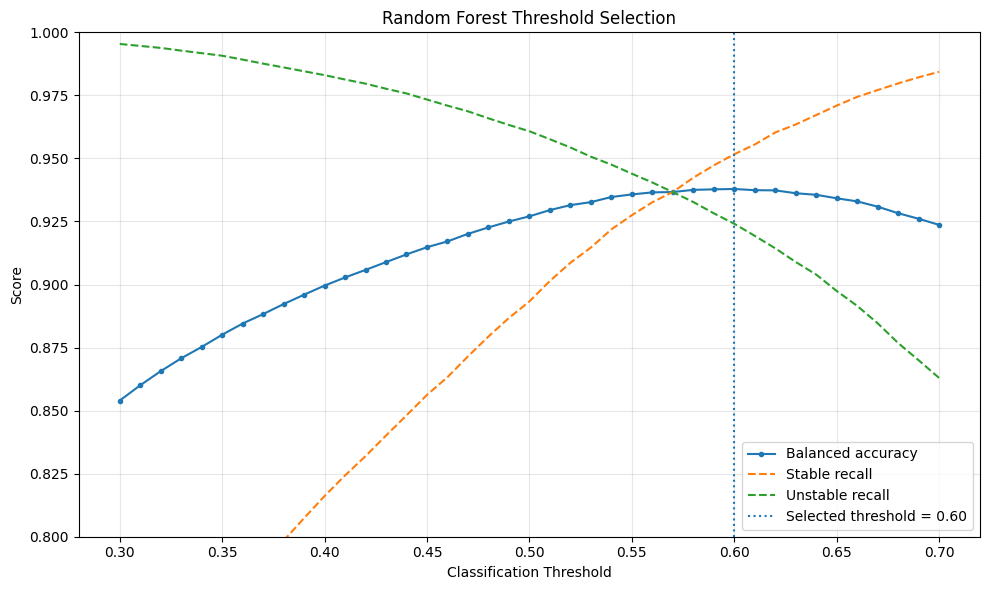

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    fine_threshold_df["Threshold"],
    fine_threshold_df["Balanced accuracy"],
    marker="o",
    markersize=3,
    label="Balanced accuracy"
)

plt.plot(
    fine_threshold_df["Threshold"],
    fine_threshold_df["Stable recall"],
    linestyle="--",
    label="Stable recall"
)

plt.plot(
    fine_threshold_df["Threshold"],
    fine_threshold_df["Unstable recall"],
    linestyle="--",
    label="Unstable recall"
)

plt.axvline(
    x=0.60,
    linestyle=":",
    label="Selected threshold = 0.60"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest Threshold Selection")
plt.ylim(0.80, 1.00)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

# Candidate thresholds
threshold_grid = np.round(
    np.arange(0.30, 0.701, 0.01), 2
)

# Outer folds: evaluate on groups not used for threshold selection
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

nested_results = []

for fold, (outer_train_idx, outer_val_idx) in enumerate(
    outer_cv.split(
        X_train[tau_g_features],
        y_train,
        groups=groups_train
    ),
    start=1
):
    print(f"\nProcessing outer fold {fold}/5...")

    # Separate the outer training and validation data
    X_outer_train = X_train[tau_g_features].iloc[outer_train_idx]
    y_outer_train = y_train.iloc[outer_train_idx]

    X_outer_val = X_train[tau_g_features].iloc[outer_val_idx]
    y_outer_val = y_train.iloc[outer_val_idx]

    groups_outer_train = groups_train[outer_train_idx]
    groups_outer_val = groups_train[outer_val_idx]

    # Confirm that configuration groups do not overlap
    assert len(np.intersect1d(
        groups_outer_train,
        groups_outer_val
    )) == 0, "Group leakage detected!"

    # Inner grouped cross-validation produces out-of-fold
    # probabilities for selecting a threshold
    inner_cv = StratifiedGroupKFold(
        n_splits=3,
        shuffle=True,
        random_state=100 + fold
    )

    inner_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    inner_probabilities = cross_val_predict(
        inner_model,
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
        cv=inner_cv,
        method="predict_proba",
        n_jobs=1
    )

    inner_classes = np.unique(y_outer_train.to_numpy())
    unstable_idx = np.flatnonzero(
        inner_classes == "unstable"
    )[0]

    inner_unstable_prob = inner_probabilities[:, unstable_idx]

    # Select the threshold with the highest inner balanced accuracy
    threshold_scores = []

    for threshold in threshold_grid:
        inner_predictions = np.where(
            inner_unstable_prob >= threshold,
            "unstable",
            "stable"
        )

        threshold_scores.append(
            balanced_accuracy_score(
                y_outer_train,
                inner_predictions
            )
        )

    best_threshold = threshold_grid[
        np.argmax(threshold_scores)
    ]

    # Fit the model on the entire outer training fold
    outer_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    outer_model.fit(X_outer_train, y_outer_train)

    # Evaluate on the outer validation fold
    outer_probabilities = outer_model.predict_proba(X_outer_val)

    outer_unstable_idx = list(
        outer_model.classes_
    ).index("unstable")

    outer_unstable_prob = outer_probabilities[
        :, outer_unstable_idx
    ]

    outer_predictions = np.where(
        outer_unstable_prob >= best_threshold,
        "unstable",
        "stable"
    )

    cm = confusion_matrix(
        y_outer_val,
        outer_predictions,
        labels=["stable", "unstable"]
    )

    nested_results.append({
        "Fold": fold,
        "Selected threshold": best_threshold,
        "Accuracy": accuracy_score(
            y_outer_val, outer_predictions
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_outer_val, outer_predictions
        ),
        "ROC-AUC": roc_auc_score(
            (y_outer_val == "unstable").astype(int),
            outer_unstable_prob
        ),
        "Stable recall": recall_score(
            y_outer_val,
            outer_predictions,
            pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_outer_val,
            outer_predictions,
            pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

    print(f"Selected inner threshold: {best_threshold:.2f}")
    print(
        "Outer balanced accuracy:",
        f"{nested_results[-1]['Balanced accuracy']:.4f}"
    )

# Show the results for each outer fold
nested_df = pd.DataFrame(nested_results)

print("\n=== Nested Group-Aware CV: Individual Folds ===")
print(nested_df.round(4).to_string(index=False))

# Summarize performance and fold-to-fold variation
metrics = [
    "Accuracy",
    "Balanced accuracy",
    "ROC-AUC",
    "Stable recall",
    "Unstable recall"
]

summary = pd.DataFrame({
    "Mean": nested_df[metrics].mean(),
    "Std across folds": nested_df[metrics].std(ddof=1)
})

print("\n=== Nested CV Performance Summary ===")
print(summary.round(4).to_string())

print(
    "\nMean selected threshold:",
    round(nested_df["Selected threshold"].mean(), 3)
)
print(
    "Median selected threshold:",
    round(nested_df["Selected threshold"].median(), 3)
)


Processing outer fold 1/5...
Selected inner threshold: 0.61
Outer balanced accuracy: 0.9418

Processing outer fold 2/5...
Selected inner threshold: 0.60
Outer balanced accuracy: 0.9447

Processing outer fold 3/5...
Selected inner threshold: 0.60
Outer balanced accuracy: 0.9404

Processing outer fold 4/5...
Selected inner threshold: 0.60
Outer balanced accuracy: 0.9317

Processing outer fold 5/5...
Selected inner threshold: 0.62
Outer balanced accuracy: 0.9239

=== Nested Group-Aware CV: Individual Folds ===
 Fold  Selected threshold  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
    1                0.61    0.9357             0.9418   0.9892         0.9640           0.9195                    491           126
    2                0.60    0.9424             0.9447   0.9879         0.9528           0.9365                    390           163
    3                0.60    0.9399             0.9404   0.9879         0.9423         

In [51]:
# Sum errors across the five outer validation folds
false_alarms = int(nested_df["False alarms"].sum())
unstable_missed = int(
    nested_df["Unstable cases missed"].sum()
)

# Each training observation appeared in one outer validation fold
stable_total = int((y_train == "stable").sum())
unstable_total = int((y_train == "unstable").sum())

# Class order: stable, unstable
true_stable = stable_total - false_alarms
true_unstable = unstable_total - unstable_missed

pooled_cm = np.array([
    [true_stable, false_alarms],
    [unstable_missed, true_unstable]
])

print("=== Pooled Outer-Fold Confusion Matrix ===")
print("Class order: stable, unstable")
print(pooled_cm)

print("\nTotal validation observations:", pooled_cm.sum())
print("Correct stable predictions:", true_stable)
print("False alarms:", false_alarms)
print("Unstable cases missed:", unstable_missed)
print("Correct unstable predictions:", true_unstable)

# Calculate metrics from the pooled counts
pooled_stable_recall = true_stable / stable_total
pooled_unstable_recall = true_unstable / unstable_total
pooled_accuracy = (
    true_stable + true_unstable
) / pooled_cm.sum()

pooled_balanced_accuracy = (
    pooled_stable_recall + pooled_unstable_recall
) / 2

print(f"\nPooled accuracy: {pooled_accuracy:.4f}")
print(
    "Pooled balanced accuracy:",
    f"{pooled_balanced_accuracy:.4f}"
)
print(f"Pooled stable recall: {pooled_stable_recall:.4f}")
print(f"Pooled unstable recall: {pooled_unstable_recall:.4f}")

=== Pooled Outer-Fold Confusion Matrix ===
Class order: stable, unstable
[[16547   829]
 [ 2423 28201]]

Total validation observations: 48000
Correct stable predictions: 16547
False alarms: 829
Unstable cases missed: 2423
Correct unstable predictions: 28201

Pooled accuracy: 0.9323
Pooled balanced accuracy: 0.9366
Pooled stable recall: 0.9523
Pooled unstable recall: 0.9209


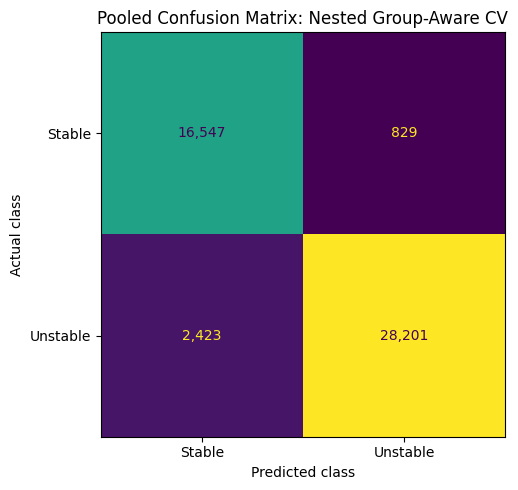

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=pooled_cm,
    display_labels=["Stable", "Unstable"]
)

display.plot(
    ax=ax,
    values_format=",d",
    colorbar=False
)

ax.set_title(
    "Pooled Confusion Matrix: Nested Group-Aware CV"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()

plt.savefig(
    "nested_cv_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()